In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

In [3]:
# 데이터 불러오기
iris = load_iris()
X = iris.data
y = to_categorical(iris.target)

In [4]:
# 데이터 전처리
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# 데이터 분할
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_val, y_val, test_size=1/3, random_state=42)

# 1. 활성화 함수 비교 (Sigmoid vs. ReLU)

### sigmoid 모델 구성 및 학습

In [5]:
model_sigmoid = Sequential()
model_sigmoid.add(Dense(5, activation='sigmoid', input_shape=(4,)))
model_sigmoid.add(Dense(5, activation='sigmoid'))
model_sigmoid.add(Dense(3, activation='softmax'))

model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [6]:
model_sigmoid.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 5)                 25        
                                                                 
 dense_1 (Dense)             (None, 5)                 30        
                                                                 
 dense_2 (Dense)             (None, 3)                 18        
                                                                 
Total params: 73 (292.00 Byte)
Trainable params: 73 (292.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [7]:
history_sigmoid = model_sigmoid.fit(
    X_train, y_train,
    epochs=200,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/200


7/7 [==============================] - 0s 17ms/step - loss: 1.1390 - accuracy: 0.3524 - val_loss: 1.1295 - val_accuracy: 0.2667
Epoch 2/200
7/7 [==============================] - 0s 4ms/step - loss: 1.1324 - accuracy: 0.3524 - val_loss: 1.1239 - val_accuracy: 0.2667
Epoch 3/200
7/7 [==============================] - 0s 5ms/step - loss: 1.1261 - accuracy: 0.3524 - val_loss: 1.1196 - val_accuracy: 0.2667
Epoch 4/200
7/7 [==============================] - 0s 5ms/step - loss: 1.1216 - accuracy: 0.3524 - val_loss: 1.1157 - val_accuracy: 0.2667
Epoch 5/200
7/7 [==============================] - 0s 4ms/step - loss: 1.1156 - accuracy: 0.3524 - val_loss: 1.1113 - val_accuracy: 0.2667
Epoch 6/200
7/7 [==============================] - 0s 4ms/step - loss: 1.1111 - accuracy: 0.3524 - val_loss: 1.1068 - val_accuracy: 0.2667
Epoch 7/200
7/7 [==============================] - 0s 4ms/step - loss: 1.1072 - accuracy: 0.3524 - val_loss: 1.1039 - val_accuracy: 0.2667
Epoch 8/200
7/7 [=======

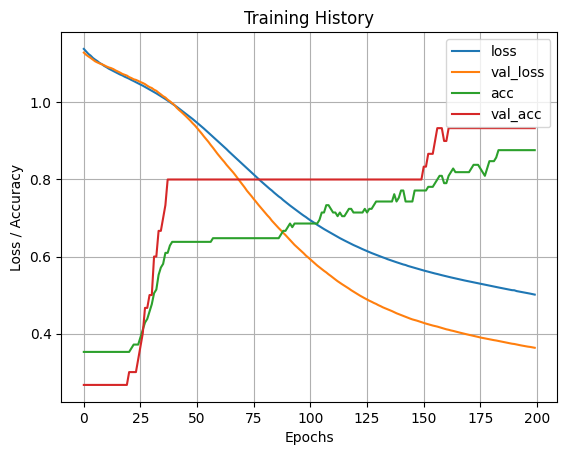

In [8]:
# 학습 과정 시각화
import matplotlib.pyplot as plt
plt.plot(history_sigmoid.history['loss'], label='loss')
plt.plot(history_sigmoid.history['val_loss'], label='val_loss')
plt.plot(history_sigmoid.history['accuracy'], label='acc')
plt.plot(history_sigmoid.history['val_accuracy'], label='val_acc')
plt.xlabel('Epochs')
plt.ylabel('Loss / Accuracy')
plt.legend()
plt.title('Training History')
plt.grid(True)
plt.show()

In [9]:
# 손실 및 정확도 계산
train_loss_sigmoid, train_acc_sigmoid = model_sigmoid.evaluate(X_train, y_train, verbose=0)
test_loss_sigmoid, test_acc_sigmoid = model_sigmoid.evaluate(X_test, y_test, verbose=0)

In [10]:
print(f"  훈련 손실: {train_loss_sigmoid:.4f}, 훈련 정확도: {train_acc_sigmoid:.4f}")
print(f"  시험 손실:  {test_loss_sigmoid:.4f}, 시험 정확도:  {test_acc_sigmoid:.4f}")

  훈련 손실: 0.5004, 훈련 정확도: 0.8762
  시험 손실:  0.5595, 시험 정확도:  0.7333


In [11]:
y_test_pred_probs = model_sigmoid.predict(X_test)
y_test_pred_sigmoid = np.argmax(y_test_pred_probs, axis=1)
y_test_true = np.argmax(y_test, axis=1)

1/1 [==============================] - 0s 41ms/step


In [12]:
confusion_matrix(y_test_true, y_test_pred_sigmoid)

array([[3, 0, 0],
       [0, 3, 4],
       [0, 0, 5]], dtype=int64)

### ReLU 모델 구성 및 학습

In [13]:
model_relu = Sequential()
model_relu.add(Dense(5, activation='relu', input_shape=(4,)))
model_relu.add(Dense(5, activation='relu'))
model_relu.add(Dense(3, activation='softmax'))
model_relu.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [14]:
model_relu.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 5)                 25        
                                                                 
 dense_4 (Dense)             (None, 5)                 30        
                                                                 
 dense_5 (Dense)             (None, 3)                 18        
                                                                 
Total params: 73 (292.00 Byte)
Trainable params: 73 (292.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [15]:
history_relu = model_relu.fit(
    X_train, y_train,
    epochs=200,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/200
7/7 [==============================] - 0s 15ms/step - loss: 1.1793 - accuracy: 0.3524 - val_loss: 1.2995 - val_accuracy: 0.2000
Epoch 2/200
7/7 [==============================] - 0s 5ms/step - loss: 1.1528 - accuracy: 0.3524 - val_loss: 1.2678 - val_accuracy: 0.2000
Epoch 3/200
7/7 [==============================] - 0s 4ms/step - loss: 1.1304 - accuracy: 0.3429 - val_loss: 1.2391 - val_accuracy: 0.2000
Epoch 4/200
7/7 [==============================] - 0s 5ms/step - loss: 1.1094 - accuracy: 0.3333 - val_loss: 1.2146 - val_accuracy: 0.2000
Epoch 5/200
7/7 [==============================] - 0s 4ms/step - loss: 1.0918 - accuracy: 0.3333 - val_loss: 1.1924 - val_accuracy: 0.2000
Epoch 6/200
7/7 [==============================] - 0s 5ms/step - loss: 1.0759 - accuracy: 0.3333 - val_loss: 1.1726 - val_accuracy: 0.2000
Epoch 7/200
7/7 [==============================] - 0s 4ms/step - loss: 1.0596 - accuracy: 0.3333 - val_loss: 1.1554 - val_accuracy: 0.2333
Epoch 8/200
7/7 [=========

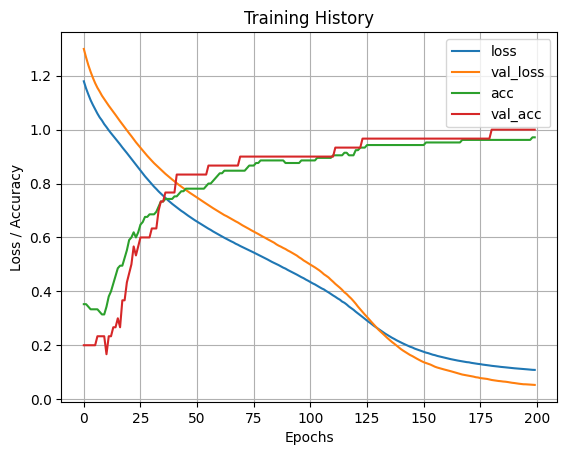

In [16]:
# 학습 과정 시각화
plt.plot(history_relu.history['loss'], label='loss')
plt.plot(history_relu.history['val_loss'], label='val_loss')
plt.plot(history_relu.history['accuracy'], label='acc')
plt.plot(history_relu.history['val_accuracy'], label='val_acc')
plt.xlabel('Epochs')
plt.ylabel('Loss / Accuracy')
plt.legend()
plt.title('Training History')
plt.grid(True)
plt.show()

In [17]:
train_loss_relu, train_acc_relu = model_relu.evaluate(X_train, y_train, verbose=0)
test_loss_relu, test_acc_relu = model_relu.evaluate(X_test, y_test, verbose=0)

In [18]:
print(f"  훈련 손실: {train_loss_relu:.4f}, 훈련 정확도: {train_acc_relu:.4f}")
print(f"  시험 손실:  {test_loss_relu:.4f}, 시험 정확도:  {test_acc_relu:.4f}")

  훈련 손실: 0.1076, 훈련 정확도: 0.9714
  시험 손실:  0.0863, 시험 정확도:  1.0000


In [19]:
y_test_pred_probs = model_relu.predict(X_test)
y_test_pred_relu = np.argmax(y_test_pred_probs, axis=1)
y_test_true = np.argmax(y_test, axis=1)

1/1 [==============================] - 0s 27ms/step


In [20]:
confusion_matrix(y_test_true, y_test_pred_relu)

array([[3, 0, 0],
       [0, 7, 0],
       [0, 0, 5]], dtype=int64)

# 2. 가중치 초기화 비교

In [7]:
from tensorflow.keras.initializers import Constant, RandomNormal, GlorotNormal, HeNormal

**4가지 가중치 초기화 방법**
- Constant: 모든 가중치를 특정 상수(예: 0)로 초기화
- RandomNormal: 정규분포를 따르는 난수로 초기화
- GlorotNormal: 세이비어(Xavier) 정규분포 초기화
- HeNormal: 히(He) 정규분포 초기화

In [8]:
# 실험할 초기화 방법 4가지를 딕셔너리로 정의
initializers = {
    "상수(0)": Constant(0.0),                       # 모든 가중치를 0으로 초기화
    "정규분포": RandomNormal(mean=0.0, stddev=1.0), # 표준 정규분포
    "세이비어": GlorotNormal(),                     # Glorot (Xavier) 초기화
    "히": HeNormal()                               # He 초기화
}

# 학습 기록과 모델을 저장할 딕셔너리
histories = {}
models = {}

In [9]:
# 4개의 다른 초깃값 실험 
for name, history in initializers.items():

    print(f"\n{name} 초기값")
    
    model = Sequential([
        Dense(5, activation='relu', kernel_initializer=initializers[name], input_shape=(4,)),
        Dense(5, activation='relu', kernel_initializer=initializers[name]),
        Dense(3, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train, y_train, epochs=500, batch_size=16, validation_data=(X_val, y_val), verbose=0)

    histories[name] = history
    models[name] = model


상수(0) 초기값





정규분포 초기값

세이비어 초기값

히 초기값


In [10]:
for name, model in models.items():
    # 예측
    y_pred = np.argmax(model.predict(X_test), axis=1) # 테스트 데이터로 예측을 수행 ->
                                                      # np.argmax(..., axis=1): 확률 중 가장 높은 값의 인덱스를 반환
    y_true = np.argmax(y_test, axis=1)                # 실제 정답도 인덱스로 변환

    print(f"\n{name} 초기값 모델 평가:")
    
    # 정확도 출력
    acc = accuracy_score(y_true, y_pred)
    print(f" 테스트 정확도: {acc:.4f}")

    # 혼동행렬
    cm = confusion_matrix(y_true, y_pred)
    print(f" 혼동 행렬: \n{cm}")

1/1 [==============================] - 0s 57ms/step

상수(0) 초기값 모델 평가:
 테스트 정확도: 0.3333
 혼동 행렬: 
[[0 0 3]
 [0 0 7]
 [0 0 5]]
1/1 [==============================] - 0s 38ms/step

정규분포 초기값 모델 평가:
 테스트 정확도: 1.0000
 혼동 행렬: 
[[3 0 0]
 [0 7 0]
 [0 0 5]]
1/1 [==============================] - 0s 32ms/step

세이비어 초기값 모델 평가:
 테스트 정확도: 1.0000
 혼동 행렬: 
[[3 0 0]
 [0 7 0]
 [0 0 5]]
1/1 [==============================] - 0s 35ms/step

히 초기값 모델 평가:
 테스트 정확도: 1.0000
 혼동 행렬: 
[[3 0 0]
 [0 7 0]
 [0 0 5]]


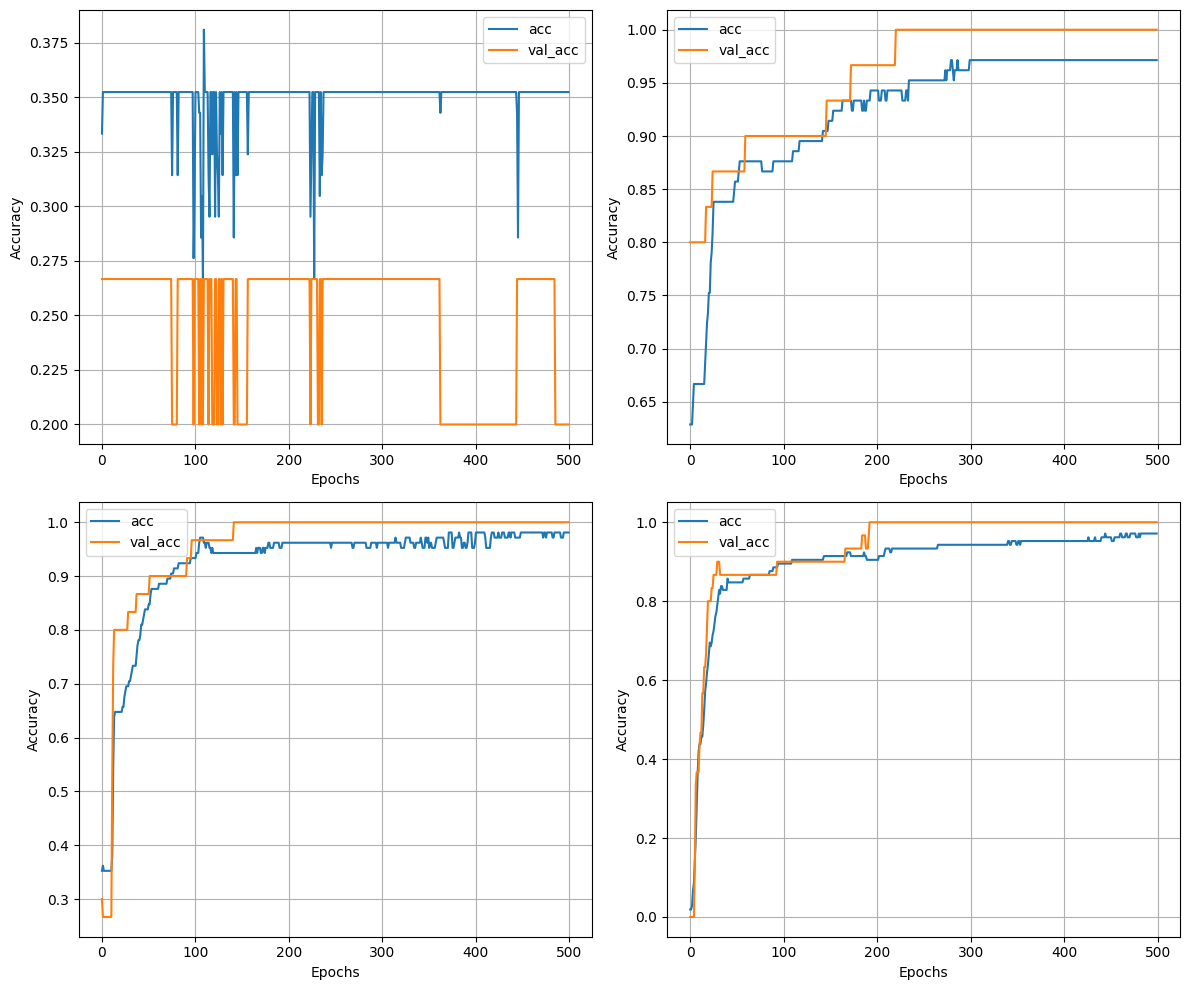

In [11]:
# 정확도 그래프 시각화
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
axs = axs.ravel()

for i, (name, history) in enumerate(histories.items()):
    axs[i].plot(history.history['accuracy'], label='acc')
    axs[i].plot(history.history['val_accuracy'], label='val_acc')
    # axs[i].set_title(f"{name} 초기값")
    axs[i].set_xlabel("Epochs")
    axs[i].set_ylabel("Accuracy")
    axs[i].legend()
    axs[i].grid(True)

plt.tight_layout()
plt.show()

- Top-left (axs[0]): "상수(0)" (Constant(0.0))
- Top-right (axs[1]): "정규분포" (RandomNormal)
- Bottom-left (axs[2]): "세이비어" (GlorotNormal)
- Bottom-right (axs[3]): "히" (HeNormal)

# 3. 최적화 방법론 선택 (옵티마이저 SGD 와 Adam)

In [7]:
# 최적화 알고리즘
optimizers = {
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.01),
    "Adam": tf.keras.optimizers.Adam()
}

In [8]:
histories = {}
models = {}

In [10]:
from tensorflow.keras.initializers import GlorotNormal

for name, opt in optimizers.items():
    model = Sequential()
    model.add(Dense(5, activation='relu', kernel_initializer=GlorotNormal(), input_shape=(4,)))
    model.add(Dense(5, activation='relu', kernel_initializer=GlorotNormal()))
    model.add(Dense(3, activation='softmax'))

    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

    history = model.fit(
        X_train, y_train,
        epochs=1000,
        batch_size=16,
        validation_data=(X_val, y_val),
        verbose=0
    )

    histories[name] = history
    models[name] = model

In [11]:
for name, model in models.items():
    print(f"\n {name} 옵티마이저 테스트 결과:")

    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    acc = accuracy_score(y_true, y_pred)
    print(f" 정확도: {acc:.4f}")

    cm = confusion_matrix(y_true, y_pred)
    print(f" 혼동 행렬 : \n{cm}")


 SGD 옵티마이저 테스트 결과:
1/1 [==============================] - 0s 62ms/step
 정확도: 1.0000
 혼동 행렬 : 
[[3 0 0]
 [0 7 0]
 [0 0 5]]

 Adam 옵티마이저 테스트 결과:
1/1 [==============================] - 0s 33ms/step
 정확도: 1.0000
 혼동 행렬 : 
[[3 0 0]
 [0 7 0]
 [0 0 5]]


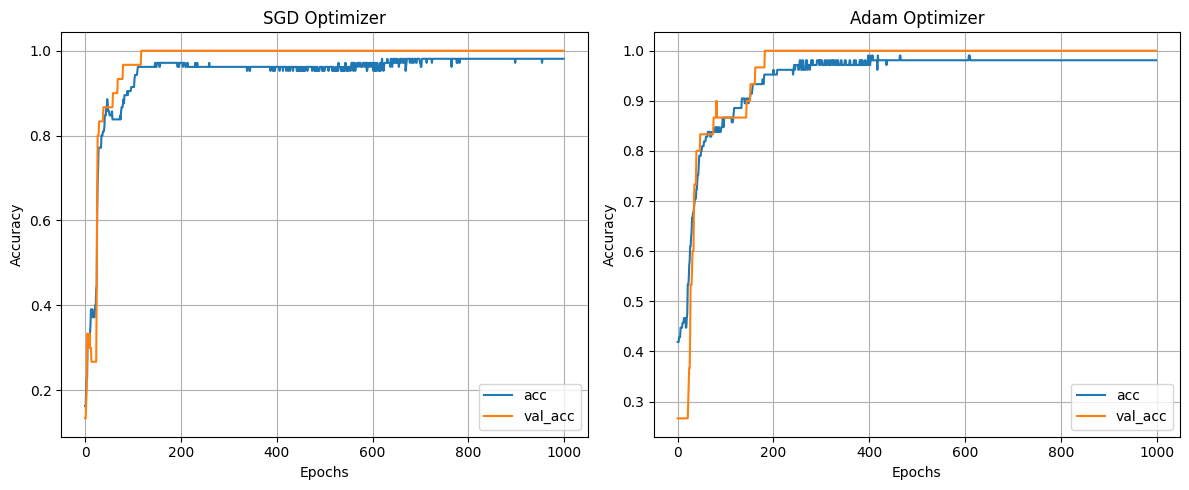

In [12]:
plt.figure(figsize=(12, 5))

for i, name in enumerate(histories):
    plt.subplot(1, 2, i+1)
    plt.plot(histories[name].history['accuracy'], label='acc')
    plt.plot(histories[name].history['val_accuracy'], label='val_acc')
    plt.title(f"{name} Optimizer")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# 4. 조기학습종료

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

In [15]:
from tensorflow.keras.initializers import HeNormal

model = Sequential()
model.add(Dense(5, activation='relu', kernel_initializer=HeNormal(), input_shape=(4,)))
model.add(Dense(5, activation='relu', kernel_initializer=HeNormal()))
model.add(Dense(3, activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(
    monitor='val_loss',       # 모니터 기준: 검증 정확도
    patience=10,              # 성능이 개선되지 않아도 기다리는 에폭 수
    restore_best_weights=True # 가장 좋은 가중치로 복원
)

In [16]:
history = model.fit(
    X_train, y_train,
    epochs=1000,
    batch_size=16,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/1000
7/7 [==============================] - 0s 19ms/step - loss: 1.5337 - accuracy: 0.2952 - val_loss: 1.0291 - val_accuracy: 0.5333
Epoch 2/1000
7/7 [==============================] - 0s 7ms/step - loss: 1.4836 - accuracy: 0.2952 - val_loss: 0.9997 - val_accuracy: 0.5333
Epoch 3/1000
7/7 [==============================] - 0s 5ms/step - loss: 1.4369 - accuracy: 0.2952 - val_loss: 0.9722 - val_accuracy: 0.5333
Epoch 4/1000
7/7 [==============================] - 0s 5ms/step - loss: 1.3927 - accuracy: 0.2952 - val_loss: 0.9452 - val_accuracy: 0.5333
Epoch 5/1000
7/7 [==============================] - 0s 6ms/step - loss: 1.3487 - accuracy: 0.2952 - val_loss: 0.9202 - val_accuracy: 0.5333
Epoch 6/1000
7/7 [==============================] - 0s 5ms/step - loss: 1.3117 - accuracy: 0.2952 - val_loss: 0.8965 - val_accuracy: 0.5333
Epoch 7/1000
7/7 [==============================] - 0s 5ms/step - loss: 1.2757 - accuracy: 0.2952 - val_loss: 0.8738 - val_accuracy: 0.5333
Epoch 8/1000
7/7 [=

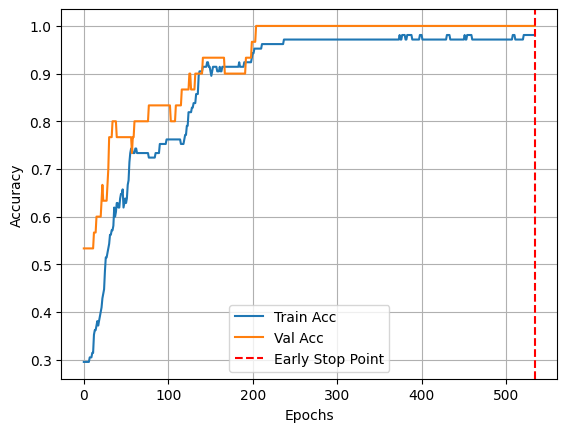

In [17]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.axvline(x=len(history.history['loss'])-1, color='red', linestyle='--', label='Early Stop Point')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

1/1 [==============================] - 0s 40ms/step


In [19]:
accuracy_score(y_true, y_pred)

1.0

In [20]:
confusion_matrix(y_true, y_pred)

array([[3, 0, 0],
       [0, 7, 0],
       [0, 0, 5]], dtype=int64)

# 5. 드롭아웃

In [21]:
from tensorflow.keras.layers import Dropout

In [22]:
model_with_dropout = Sequential()
model_with_dropout.add(Dense(5, activation='relu', kernel_initializer=HeNormal(), input_shape=(4,)))
model_with_dropout.add(Dropout(0.3))
model_with_dropout.add(Dense(5, activation='relu', kernel_initializer=HeNormal()))
model_with_dropout.add(Dropout(0.3))
model_with_dropout.add(Dense(3, activation='softmax'))

model_with_dropout.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [23]:
model_with_dropout.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_9 (Dense)             (None, 5)                 25        
                                                                 
 dropout (Dropout)           (None, 5)                 0         
                                                                 
 dense_10 (Dense)            (None, 5)                 30        
                                                                 
 dropout_1 (Dropout)         (None, 5)                 0         
                                                                 
 dense_11 (Dense)            (None, 3)                 18        
                                                                 
Total params: 73 (292.00 Byte)
Trainable params: 73 (292.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [24]:
history_with_dropout = model_with_dropout.fit(
    X_train, y_train,
    epochs=1000,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=0
)

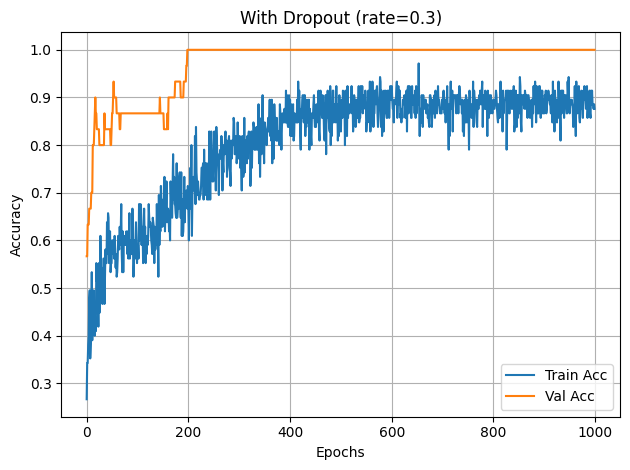

In [25]:
plt.plot(history_with_dropout.history['accuracy'], label='Train Acc')
plt.plot(history_with_dropout.history['val_accuracy'], label='Val Acc')
plt.title("With Dropout (rate=0.3)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [26]:
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

acc = accuracy_score(y_true, y_pred)
print(f"테스트 정확도: {acc:.4f}")

cm = confusion_matrix(y_true, y_pred)
print(f"혼동행렬: \n{cm}")

1/1 [==============================] - 0s 16ms/step
테스트 정확도: 1.0000
혼동행렬: 
[[3 0 0]
 [0 7 0]
 [0 0 5]]


# 6. 배치 정규화(Batch Normalization)

In [6]:
from tensorflow.keras.layers import BatchNormalization, Activation

### He + 배치 정규화

In [8]:
from tensorflow.keras.initializers import HeNormal
model_he = Sequential()
model_he.add(Dense(5, kernel_initializer=HeNormal(), input_shape=(4,)))
model_he.add(BatchNormalization())
model_he.add(Activation('relu'))

model_he.add(Dense(5, kernel_initializer=HeNormal()))
model_he.add(BatchNormalization())
model_he.add(Activation('relu'))

model_he.add(Dense(3, activation='softmax'))

model_he.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [9]:
model_he.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 5)                 25        
                                                                 
 batch_normalization (Batch  (None, 5)                 20        
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 5)                 0         
                                                                 
 dense_1 (Dense)             (None, 5)                 30        
                                                                 
 batch_normalization_1 (Bat  (None, 5)                 20        
 chNormalization)                                                
                                                                 
 activation_1 (Activation)   (None, 5)                

In [10]:
history_he = model_he.fit(
    X_train, y_train,
    epochs=500,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=0
)

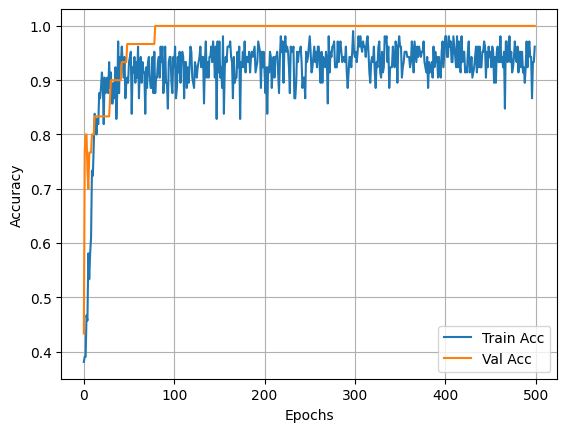

In [11]:
plt.plot(history_he.history['accuracy'], label='Train Acc')
plt.plot(history_he.history['val_accuracy'], label='Val Acc')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

In [19]:
y_pred = np.argmax(model_he.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

acc = accuracy_score(y_true, y_pred)
print(f"\n He + 배치 정규화 테스트 정확도: {acc:.4f}")

cm = confusion_matrix(y_true, y_pred)
print(f"\n 혼동행렬: \n{cm}")

1/1 [==============================] - 0s 16ms/step

 He + 배치 정규화 테스트 정확도: 1.0000

 혼동행렬: 
[[3 0 0]
 [0 7 0]
 [0 0 5]]


### Normal + 배치 정규화

In [27]:
from tensorflow.keras.initializers import RandomNormal

model_normal = Sequential()
model_normal.add(Dense(5, kernel_initializer=RandomNormal(stddev=1.0), input_shape=(4,)))
model_normal.add(BatchNormalization())
model_normal.add(Activation('relu'))

model_normal.add(Dense(5, kernel_initializer=RandomNormal(stddev=1.0)))
model_normal.add(BatchNormalization())
model_normal.add(Activation('relu'))

model_normal.add(Dense(3, activation='softmax'))

model_normal.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [28]:
model_normal.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_9 (Dense)             (None, 5)                 25        
                                                                 
 batch_normalization_4 (Bat  (None, 5)                 20        
 chNormalization)                                                
                                                                 
 activation_6 (Activation)   (None, 5)                 0         
                                                                 
 dense_10 (Dense)            (None, 5)                 30        
                                                                 
 batch_normalization_5 (Bat  (None, 5)                 20        
 chNormalization)                                                
                                                                 
 activation_7 (Activation)   (None, 5)                

In [29]:
history_normal = model_normal.fit(
    X_train, y_train,
    epochs=500,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=0
)

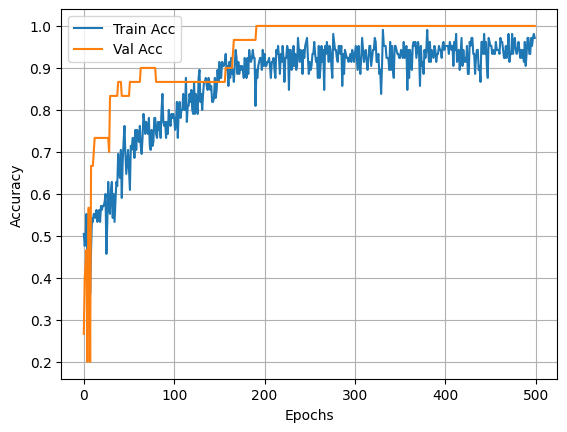

In [30]:
plt.plot(history_normal.history['accuracy'], label='Train Acc')
plt.plot(history_normal.history['val_accuracy'], label='Val Acc')
# plt.title("정규분포 초기값 + 배치 정규화")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

In [31]:
y_pred = np.argmax(model_normal.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

acc = accuracy_score(y_true, y_pred)
print(f"\n Normal + 배치 정규화 테스트 정확도: {acc:.4f}")

cm = confusion_matrix(y_true, y_pred)
print(f"\n 혼동행렬: \n{cm}")

1/1 [==============================] - 0s 52ms/step

 Normal + 배치 정규화 테스트 정확도: 0.9333

 혼동행렬: 
[[3 0 0]
 [0 6 1]
 [0 0 5]]


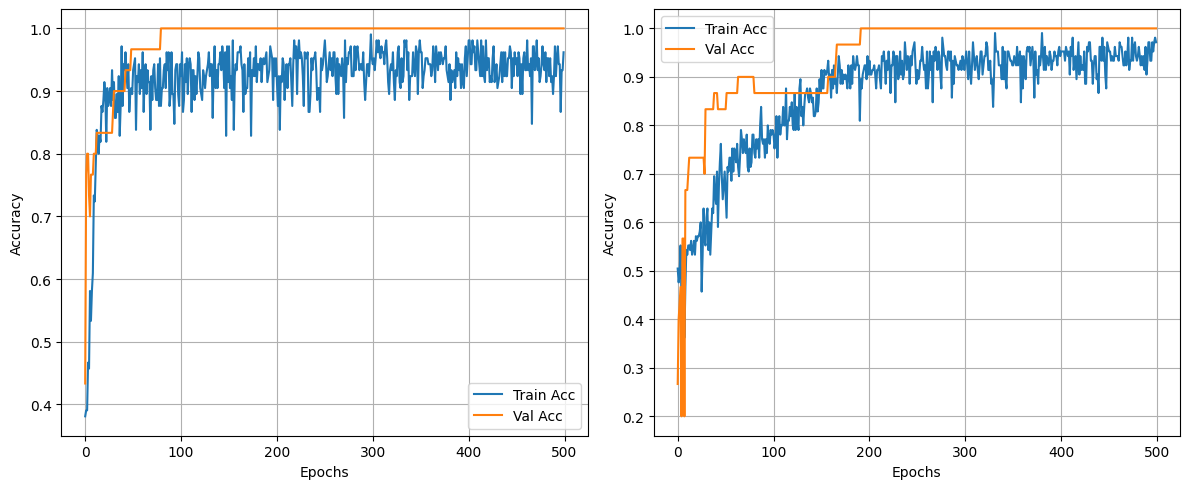

In [32]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_he.history['accuracy'], label='Train Acc')
plt.plot(history_he.history['val_accuracy'], label='Val Acc')
# plt.title("He 초기값 + 배치 정규화")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_normal.history['accuracy'], label='Train Acc')
plt.plot(history_normal.history['val_accuracy'], label='Val Acc')
# plt.title("정규분포 초기값 + 배치 정규화")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()